# Shirt Sponsor Churn — Phase 2: What Happens When a Sector Disappears

**Business question:** when a whole sector is banned from a sponsorship market, who takes its place, and how long do they stay?

**Natural experiment:**
- **Spain:** Real Decreto 958/2020 let existing betting sponsorships run only until **31 August 2021**, so 2021/22 was LaLiga's first season with no betting brand on the front of a shirt.
- **England:** Premier League clubs agreed on 13 April 2023 to withdraw gambling sponsors from the front of matchday shirts from **2026/27**.

LaLiga went through the change five seasons earlier, so it shows what the Premier League is about to go through.

| # | Analysis | Question |
|---|---|---|
| 1 | Sector mix over time | How big was betting, and what replaced it? |
| 2 | Churn rates | How often do clubs change their main shirt sponsor? |
| 3 | Kaplan–Meier by sector | How long does a sponsorship last, by sector? |
| 4 | Discrete-time hazard model | What predicts a sponsor leaving: sector, relegation, promotion, foreign brand? |
| 5 | The betting-ban cases | What exactly happened at each club that lost its betting sponsor? |
| 6 | LinkedIn charts | Four 1080×1350 charts |

**Definitions (fixed before looking at results):**
- *Sponsor* = the **canonical brand** on the front of the shirt (so *Fly Emirates* → *Emirates* is a renewal, not a change).
- *Change* = the club's brand in season *t+1* differs from season *t*, observed in any of the four divisions. A club that drops to the third tier, or a Segunda season missing from Wikipedia (2005–2009), is **censored**, not counted as a change.
- *Relegation / promotion* are taken from the division the club plays in the next season, not from table markers.

## 0. Setup

In [1]:
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

warnings.filterwarnings('ignore', category=FutureWarning)
pd.set_option('display.width', 180)
pd.set_option('display.max_columns', 30)

try:
    from google.colab import drive
    drive.mount('/content/drive')
    BASE = Path('/content/drive/MyDrive/proyecto_patrocinios')
except ImportError:
    BASE = Path.cwd() / 'proyecto_patrocinios'

PROC, MANUAL = BASE / 'data' / 'processed', BASE / 'data' / 'manual'
OUT = BASE / 'phase2'
FIG = OUT / 'figures'
FIG.mkdir(parents=True, exist_ok=True)
print('Reading from', BASE)

CHART_LANG = 'es'
AUTHOR = 'Miguel R.'
CURRENT_SEASON = 2026
BAN = {'Spain': 2021, 'England': 2026}       # first season without betting on the shirt front

Reading from proyecto_patrocinios


In [2]:
%pip install -q lifelines statsmodels

In [3]:
from lifelines import KaplanMeierFitter
import statsmodels.formula.api as smf

panel = pd.read_csv(PROC / 'club_seasons.csv')
tags = pd.read_csv(MANUAL / 'sponsor_tags.csv')

d = panel.merge(tags[['sponsor_key', 'brand', 'sector', 'brand_country', 'notes']], on='sponsor_key', how='left')
untagged = d[(d.sponsor != 'NO SPONSOR') & d.brand.isna()]
assert untagged.empty, f'{len(untagged)} club-seasons without a tag: {untagged.sponsor.unique()[:10]}'

nos = (d.sponsor == 'NO SPONSOR') | (d.brand == 'NO SPONSOR')
d.loc[nos, ['brand', 'sector', 'brand_country']] = ['NO SPONSOR', 'no sponsor', '']
d['league'] = d.country.map({'ESP': 'Spain', 'ENG': 'England'})
home = d.country.map({'ESP': 'ESP', 'ENG': 'GBR'})
d['foreign'] = np.where(nos, np.nan, (d.brand_country != home).astype(float))

SECTOR_GROUP = {'betting & gaming': 'Betting', 'crypto & trading apps': 'Crypto & trading',
                'airline & travel': 'Airlines & travel', 'banking & insurance': 'Banking & insurance',
                'public body & tourism board': 'Regions & tourism boards', 'no sponsor': 'No sponsor'}
d['sector_group'] = d.sector.map(SECTOR_GROUP).fillna('Other sectors')

d = d.sort_values(['team', 'season']).reset_index(drop=True)
g = d.groupby('team')
d['next_season'] = g.season.shift(-1)
d['next_brand'] = g.brand.shift(-1)
d['next_tier'] = g.tier.shift(-1)
d['obs_next'] = d.next_season == d.season + 1
d['prev_obs'] = g.season.shift(1) == d.season - 1
d['changed'] = d.obs_next & (d.next_brand != d.brand)
d['relegated_end'] = d.obs_next & (d.tier == 1) & (d.next_tier == 2)
d['promoted_end'] = d.obs_next & (d.tier == 2) & (d.next_tier == 1)
d['spell_id'] = ((g.brand.shift(1) != d.brand) | ~d.prev_obs).cumsum()
d['spell_age'] = d.groupby('spell_id').cumcount() + 1

print(f'{len(d):,} club-seasons | {d.team.nunique()} clubs | {d[~nos].brand.nunique()} brands')
print(d.groupby(['league', 'tier']).season.agg(['min', 'max', 'size']))

1,782 club-seasons | 141 clubs | 577 brands
               min   max  size
league  tier                  
England 1     2005  2026   440
        2     2005  2026   528
Spain   1     2005  2026   440
        2     2010  2026   374


### Chart style

In [4]:
RED, BLUE, VIOLET, AQUA, YELLOW, GREEN = '#E34948', '#2E6DB4', '#6250D6', '#1BAF7A', '#EDA100', '#008300'
GREY, LIGHT, INK, MUTED = '#BDBDBD', '#EFEFEF', '#1A1A1A', '#6B6B6B'
LEAGUE_COLOR = {'Spain': RED, 'England': BLUE}
SECTOR_COLOR = {'Betting': RED, 'Crypto & trading': VIOLET, 'Banking & insurance': AQUA,
                'Regions & tourism boards': YELLOW, 'Airlines & travel': GREY, 'Other sectors': GREY, 'No sponsor': 'white'}

plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'grid.alpha': 0.22,
                     'figure.dpi': 110, 'legend.frameon': False, 'axes.titleweight': 'bold',
                     'axes.titlelocation': 'left', 'font.size': 10.5, 'xtick.color': MUTED, 'ytick.color': MUTED})

def t(es, en):
    return es if CHART_LANG == 'es' else en

def num(x, dec=0):
    s = f'{x:,.{dec}f}'
    return s.replace(',', 'X').replace('.', ',').replace('X', '.') if CHART_LANG == 'es' else s

def season_lbl(y):
    return f'{str(y)[-2:]}/{str(y + 1)[-2:]}'

def save(fig, name, tight=True):
    p = FIG / f'{name}.png'
    fig.savefig(p, dpi=fig.dpi, bbox_inches='tight' if tight else None)
    print('Saved', p)

## 1. Sector mix in the top flight

Share of top-flight clubs whose main shirt sponsor belongs to each sector, by season.

In [5]:
top = d[d.tier == 1]
mix = (top.groupby(['league', 'season']).sector_group.value_counts(normalize=True)
          .rename('share').reset_index())
betting = (mix[mix.sector_group == 'Betting'].pivot(index='season', columns='league', values='share')
             .reindex(range(top.season.min(), CURRENT_SEASON + 1)).fillna(0) * 100)
display(betting.round(0).astype(int).T)

for lg, y in BAN.items():
    before = betting.loc[y - 1, lg]
    print(f'{lg}: betting on {before:.0f}% of top-flight shirts in {season_lbl(y - 1)} → {betting.loc[y, lg]:.0f}% in {season_lbl(y)}')
print(f"Peak: Spain {betting.Spain.max():.0f}% ({season_lbl(betting.Spain.idxmax())}), England {betting.England.max():.0f}% ({season_lbl(betting.England.idxmax())})")

season,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
league,,,,,,,,,,,,,,,,,,,,,,
England,5,20,20,15,35,25,35,25,15,25,35,50,45,45,50,40,45,40,40,55,55,0
Spain,0,5,10,15,25,30,15,15,10,5,10,5,15,25,50,35,0,0,0,0,0,0


Spain: betting on 35% of top-flight shirts in 20/21 → 0% in 21/22
England: betting on 55% of top-flight shirts in 25/26 → 0% in 26/27
Peak: Spain 50% (19/20), England 55% (24/25)


Saved proyecto_patrocinios/phase2/figures/diag_01_sector_mix.png


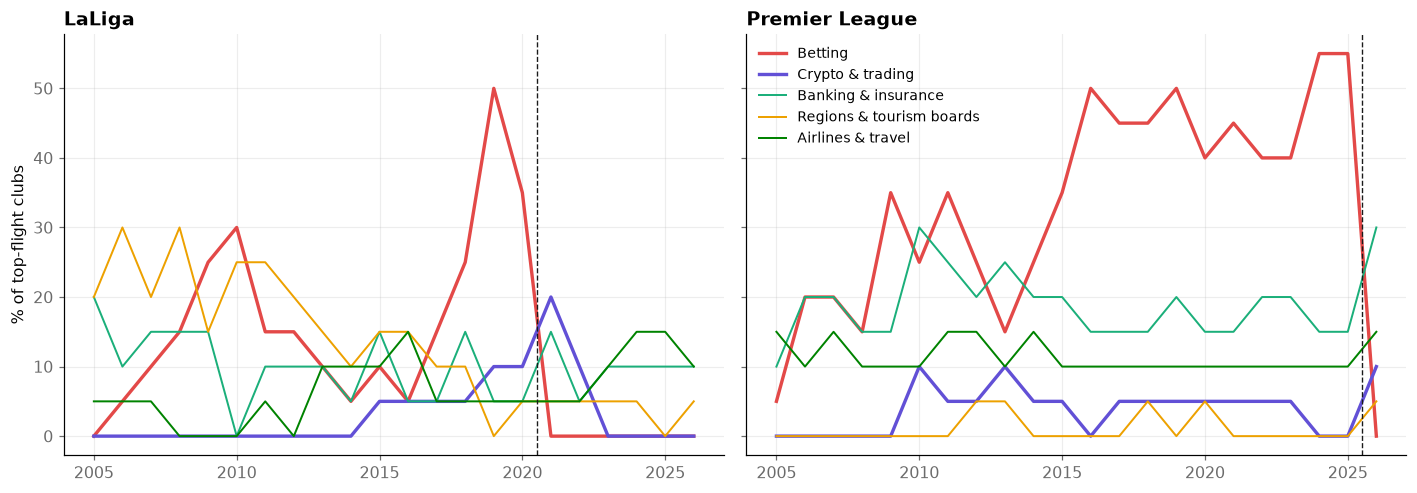

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), sharey=True)
groups = ['Betting', 'Crypto & trading', 'Banking & insurance', 'Regions & tourism boards', 'Airlines & travel']
for ax, lg in zip(axes, ['Spain', 'England']):
    w = mix[mix.league == lg].pivot(index='season', columns='sector_group', values='share').fillna(0) * 100
    for gname in groups:
        if gname in w:
            ax.plot(w.index, w[gname], lw=2.2 if gname in ('Betting', 'Crypto & trading') else 1.3,
                    color=SECTOR_COLOR[gname] if gname != 'Airlines & travel' else GREEN, label=gname)
    ax.axvline(BAN[lg] - 0.5, color=INK, ls='--', lw=0.9)
    ax.set_title('LaLiga' if lg == 'Spain' else 'Premier League')
axes[0].set_ylabel('% of top-flight clubs')
axes[1].legend(loc='upper left', fontsize=9)
fig.tight_layout()
save(fig, 'diag_01_sector_mix')
plt.show()

## 2. How often do clubs change sponsor?

Risk set: club-seasons with a sponsor and an observed next season. A change is a different brand (or no sponsor) the following season.

In [7]:
risk = d[(d.brand != 'NO SPONSOR') & d.obs_next].copy()
print(f'Club-seasons at risk: {len(risk):,} | changes: {risk.changed.sum():,} | rate: {risk.changed.mean():.1%}')
display(risk.groupby('league').changed.mean().mul(100).round(1).rename('% changing each season'))
display(risk.groupby('sector_group').changed.agg(rate='mean', n='size')
            .assign(rate=lambda x: (x.rate * 100).round(1)).sort_values('rate'))

# press check: LaLiga 2026/27, clubs already in LaLiga in 2025/26
prev = d[(d.division == 'laliga') & (d.season == CURRENT_SEASON - 1) & d.obs_next & (d.next_tier == 1)]
print(f"LaLiga {season_lbl(CURRENT_SEASON)}: {prev.changed.sum()} of {len(prev)} clubs that stayed in LaLiga changed main shirt sponsor.")

Club-seasons at risk: 1,519 | changes: 533 | rate: 35.1%


league
England    35.7
Spain      34.2
Name: % changing each season, dtype: float64

,rate,n
sector_group,,
Airlines & travel,19.6,97
Banking & insurance,28.4,201
Regions & tourism boards,28.5,130
Other sectors,35.6,744
Betting,42.8,313
Crypto & trading,61.8,34


LaLiga 26/27: 4 of 17 clubs that stayed in LaLiga changed main shirt sponsor.


## 3. How long does a sponsorship last? (Kaplan–Meier)

A **spell** is a run of consecutive seasons with the same brand at the same club. Only spells whose **start is observed** are used (the club's previous season is in the data with a different sponsor), otherwise the duration is unknown. Spells still running in 2026/27, or interrupted by a gap in the data, are censored.

In [8]:
sp = (d.groupby('spell_id')
        .agg(team=('team', 'first'), league=('league', 'first'), brand=('brand', 'first'),
             sector_group=('sector_group', 'first'), start=('season', 'min'), seasons=('season', 'size'),
             start_known=('prev_obs', 'first'), ended=('changed', 'last')))
sp = sp[(sp.brand != 'NO SPONSOR') & sp.start_known]
print(f'Spells with an observed start: {len(sp)} | ended: {sp.ended.sum()} | censored: {(~sp.ended).sum()}')

kmf = KaplanMeierFitter()
KM, km_rows = {}, []
for s, x in sp.groupby('sector_group'):
    kmf.fit(x.seasons, x.ended, label=s)
    KM[s] = kmf.survival_function_.copy()
    km_rows.append({'sector': s, 'spells': len(x), 'median_seasons': kmf.median_survival_time_,
                    'still_after_1': kmf.predict(1), 'still_after_2': kmf.predict(2), 'still_after_3': kmf.predict(3)})
kmf.fit(sp.seasons, sp.ended, label='All sectors')
KM['All sectors'] = kmf.survival_function_.copy()
km_rows.append({'sector': 'All sectors', 'spells': len(sp), 'median_seasons': kmf.median_survival_time_,
                'still_after_1': kmf.predict(1), 'still_after_2': kmf.predict(2), 'still_after_3': kmf.predict(3)})
km_table = pd.DataFrame(km_rows).set_index('sector').sort_values('median_seasons')
display(km_table.round(2))

Spells with an observed start: 530 | ended: 399 | censored: 131


,spells,median_seasons,still_after_1,still_after_2,still_after_3
sector,,,,,
Crypto & trading,22,1.0,0.36,0.18,0.06
Banking & insurance,48,2.0,0.67,0.47,0.38
Betting,146,2.0,0.69,0.30,0.17
Other sectors,257,2.0,0.67,0.43,0.27
All sectors,530,2.0,0.66,0.39,0.25
Regions & tourism boards,33,2.0,0.61,0.39,0.25
Airlines & travel,24,4.0,0.75,0.69,0.62


## 4. What predicts a sponsor leaving? (discrete-time hazard model)

Logistic regression on the club-season risk set: *P(the brand changes after season t)*.

- **Sector** (reference: *Other sectors*), **foreign brand**, **division**, **league**.
- **Relegated / promoted at the end of season t** (time-varying).
- **Spell age** (1, 2, 3, 4+ seasons), only for spells with an observed start.
- Standard errors **clustered by club**.

**Robustness:** the same model without the 17 betting sponsors that the bans *forced* out (LaLiga 2020/21 → 2021/22 and Premier League 2025/26 → 2026/27, clubs that stayed in the top flight). Otherwise the ban itself would inflate the betting effect.

In [9]:
r = risk.copy()
r['known_start'] = r.spell_id.map(d.groupby('spell_id').prev_obs.first())
r['age'] = np.where(r.known_start, np.minimum(r.spell_age, 4), np.nan)
r['changed_i'] = r.changed.astype(int)
r['relegated'] = r.relegated_end.astype(int)
r['promoted'] = r.promoted_end.astype(int)
r['sg'] = pd.Categorical(r.sector_group, categories=['Other sectors', 'Airlines & travel', 'Banking & insurance',
                                                       'Regions & tourism boards', 'Betting', 'Crypto & trading'])
r['forced'] = (r.sector == 'betting & gaming') & (r.next_tier == 1) & (
    ((r.league == 'Spain') & (r.season == BAN['Spain'] - 1)) | ((r.league == 'England') & (r.season == BAN['England'] - 1)))

FORMULA = 'changed_i ~ C(sg) + foreign + C(tier) + relegated + promoted + C(league) + C(age)'

def fit(data):
    k = data.dropna(subset=['age'])
    m = smf.logit(FORMULA, data=k).fit(disp=0, cov_type='cluster', cov_kwds={'groups': pd.factorize(k.team)[0]})
    ci = m.conf_int()
    return m, pd.DataFrame({'odds_ratio': np.exp(m.params), 'ci_lo': np.exp(ci[0]), 'ci_hi': np.exp(ci[1]),
                            'p_value': m.pvalues}).drop('Intercept')

m_all, or_all = fit(r)
m_rob, or_rob = fit(r[~r.forced])
print(f'Observations: {int(m_all.nobs)} (all) | {int(m_rob.nobs)} (without {int(r.forced.sum())} forced betting exits)')
hazard = or_all.join(or_rob, rsuffix='_robust')
display(hazard.round(3))

Observations: 1150 (all) | 1133 (without 17 forced betting exits)


,odds_ratio,ci_lo,ci_hi,p_value,odds_ratio_robust,ci_lo_robust,ci_hi_robust,p_value_robust
C(sg)[T.Airlines & travel],0.386,0.166,0.896,0.027,0.394,0.171,0.904,0.028
C(sg)[T.Banking & insurance],0.761,0.436,1.327,0.335,0.755,0.435,1.312,0.319
C(sg)[T.Regions & tourism boards],0.815,0.381,1.742,0.598,0.819,0.382,1.755,0.608
C(sg)[T.Betting],1.513,1.061,2.157,0.022,1.307,0.913,1.871,0.143
C(sg)[T.Crypto & trading],3.431,1.634,7.204,0.001,3.526,1.705,7.294,0.001
C(tier)[T.2],1.380,0.984,1.937,0.062,1.460,1.034,2.061,0.032
C(league)[T.Spain],1.154,0.832,1.601,0.390,1.107,0.796,1.541,0.546
C(age)[T.2.0],1.275,0.904,1.799,0.167,1.245,0.884,1.754,0.209
C(age)[T.3.0],1.135,0.790,1.632,0.493,1.100,0.761,1.589,0.613
C(age)[T.4.0],0.416,0.257,0.674,0.000,0.406,0.248,0.664,0.000


**How to read it:** an odds ratio above 1 means the sponsor is more likely to leave after that season; below 1, more likely to stay. Only effects that survive the robustness check are used in the post.

## 5. The betting-ban cases

Every club that had a betting sponsor in the last season before the ban, followed season by season.

In [10]:
def follow(division, base, n_after):
    clubs = d[(d.division == division) & (d.season == base) & (d.sector == 'betting & gaming')]
    rows = []
    for _, c in clubs.iterrows():
        h = d[(d.team == c.team) & (d.season.between(base, base + n_after))].set_index('season')
        row = {'team': c.team}
        for y in range(base, base + n_after + 1):
            row[y] = (h.loc[y, 'brand'], h.loc[y, 'sector_group'], int(h.loc[y, 'tier'])) if y in h.index else None
        rows.append(row)
    return pd.DataFrame(rows).set_index('team')

spain = follow('laliga', BAN['Spain'] - 1, CURRENT_SEASON - BAN['Spain'] + 1)
england = follow('premier', BAN['England'] - 1, 1)

# Replacement survival in LaLiga: first sponsor after the ban, did it last more than one season?
repl = []
for team, row in spain.iterrows():
    first = row[BAN['Spain']]
    nxt = row.get(BAN['Spain'] + 1)
    repl.append({'team': team, 'betting_brand': row[BAN['Spain'] - 1][0], 'replacement': first[0],
                 'sector': first[1], 'still_next_season': nxt is not None and nxt[0] == first[0]})
repl = pd.DataFrame(repl)
display(repl)
n_short = (~repl.still_next_season).sum()
print(f'LaLiga: {n_short} of {len(repl)} replacements lasted a single season | '
      f"crypto/trading: {(repl.sector == 'Crypto & trading').sum()} | finance & payments: {(repl.sector == 'Banking & insurance').sum()}")

eng = []
for team, row in england.iterrows():
    now = row[BAN['England']]
    eng.append({'team': team, 'betting_brand': row[BAN['England'] - 1][0],
                'sponsor_2026_27': now[0] if now else None, 'sector': now[1] if now else None,
                'division_2026_27': now[2] if now else None})
eng = pd.DataFrame(eng)
display(eng)
stayed = eng[eng.division_2026_27 == 1]
print(f'Premier League: {len(eng)} clubs had a betting sponsor in {season_lbl(BAN["England"] - 1)}; '
      f'{len(stayed)} stayed up, {(eng.division_2026_27 == 2).sum()} were relegated and kept or chose betting brands in the Championship.')

,team,betting_brand,replacement,sector,still_next_season
0,Alavés,Betway,Zotapay,Banking & insurance,False
1,Cádiz,Dafabet,Bitci,Crypto & trading,False
2,Granada,Winamax,Platzi,Other sectors,False
3,Levante,Betway,Gedesco,Banking & insurance,False
4,Real Betis,Betway,Finetwork,Other sectors,True
5,Sevilla,Marathonbet,NAGA,Crypto & trading,False
6,Valencia,bwin,Socios.com,Crypto & trading,False


LaLiga: 6 of 7 replacements lasted a single season | crypto/trading: 3 | finance & payments: 2


,team,betting_brand,sponsor_2026_27,sector,division_2026_27
0,Aston Villa,Betano,Visit Rwanda,Regions & tourism boards,1
1,Bournemouth,bj88,Vitality,Banking & insurance,1
2,Brentford,Hollywoodbets,Indeed,Other sectors,1
3,Burnley,96.com,Vertu Motors,Other sectors,2
4,Crystal Palace,NET88,Temporal,Other sectors,1
5,Everton,Stake,CMC Markets,Crypto & trading,1
6,Fulham,SBOTOP,ClickHouse,Other sectors,1
7,Nottingham Forest,Bally's,Marex,Banking & insurance,1
8,Sunderland,W88,NO SPONSOR,No sponsor,1
9,West Ham United,BoyleSports,BoyleSports,Betting,2


Premier League: 11 clubs had a betting sponsor in 25/26; 8 stayed up, 3 were relegated and kept or chose betting brands in the Championship.


### What to expect in the Premier League (projection, not a forecast)

Each new Premier League sponsor gets the one-season survival rate of its sector from the Kaplan–Meier table. The sum is the number of replacements we would expect to see still on the shirt in 2027/28 **if they behave like an average sponsor of their sector**. LaLiga's replacements did much worse than their sectors' averages, which is the warning in this projection.

In [11]:
stay = stayed[stayed.sector != 'No sponsor'].copy()
stay['p_still_2027'] = stay.sector.map(km_table.still_after_1)
expected = stay.p_still_2027.sum()
display(stay[['team', 'sponsor_2026_27', 'sector', 'p_still_2027']].round(2))
print(f'Expected still on the shirt in 2027/28: {expected:.1f} of {len(stay)} (sector averages)')
spain_base = km_table.loc[repl.sector.unique(), 'still_after_1'].mean()
print(f'For comparison, LaLiga 2021/22: sector averages implied ~{spain_base * len(repl):.1f} of {len(repl)}; actual: {repl.still_next_season.sum()} of {len(repl)}')

,team,sponsor_2026_27,sector,p_still_2027
0,Aston Villa,Visit Rwanda,Regions & tourism boards,0.61
1,Bournemouth,Vitality,Banking & insurance,0.67
2,Brentford,Indeed,Other sectors,0.67
4,Crystal Palace,Temporal,Other sectors,0.67
5,Everton,CMC Markets,Crypto & trading,0.36
6,Fulham,ClickHouse,Other sectors,0.67
7,Nottingham Forest,Marex,Banking & insurance,0.67


Expected still on the shirt in 2027/28: 4.3 of 7 (sector averages)
For comparison, LaLiga 2021/22: sector averages implied ~4.0 of 7; actual: 1 of 7


## 6. LinkedIn charts (1080 × 1350)

In [12]:
def canvas(title, subtitle, source, axes_rect=(0.10, 0.17, 0.82, 0.55)):
    fig = plt.figure(figsize=(10.8, 13.5), dpi=100, facecolor='white')
    fig.text(0.07, 0.95, title, fontsize=30, fontweight='bold', color=INK, va='top', linespacing=1.15)
    fig.text(0.07, 0.80, subtitle, fontsize=18, color=MUTED, va='top', linespacing=1.35)
    fig.text(0.07, 0.025, source, fontsize=12, color=MUTED, va='bottom', linespacing=1.4)
    fig.text(0.93, 0.09, AUTHOR, fontsize=14, color=INK, fontweight='bold', ha='right', va='bottom')
    ax = fig.add_axes(axes_rect) if axes_rect else None
    if ax is not None:
        for s in ('top', 'right'):
            ax.spines[s].set_visible(False)
        ax.tick_params(labelsize=15, colors=MUTED)
    return fig, ax

Saved proyecto_patrocinios/phase2/figures/linkedin_1_betting_share.png


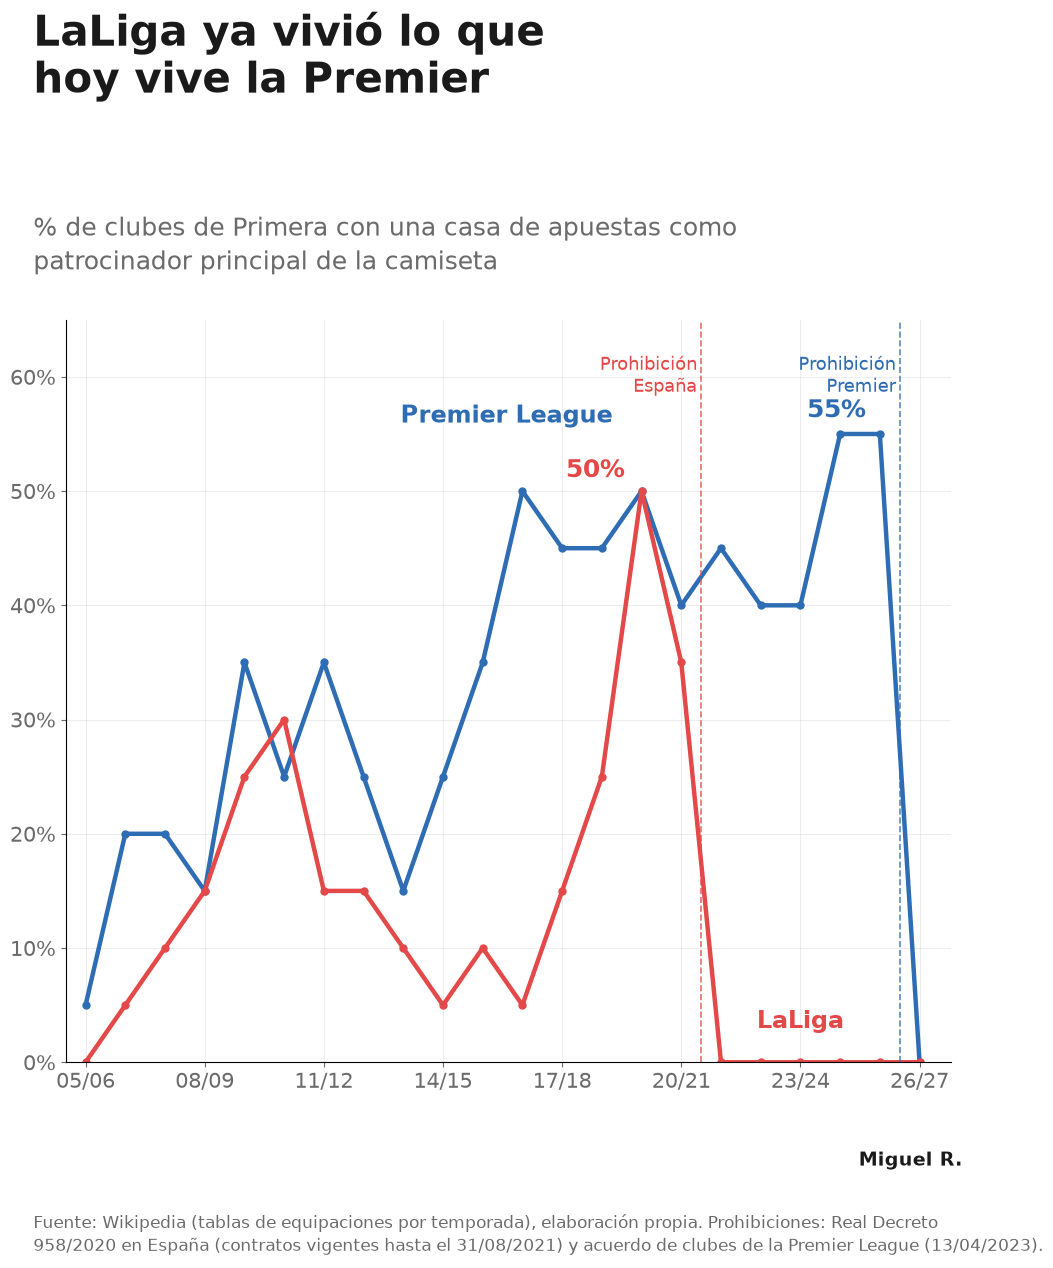

In [13]:
# Chart 1 — betting disappears from the shirts
sp_peak, en_last = betting.Spain.loc[BAN['Spain'] - 2], betting.England.loc[BAN['England'] - 1]
fig, ax = canvas(t('LaLiga ya vivió lo que\nhoy vive la Premier', 'LaLiga has already lived\nwhat the Premier League faces'),
                 t('% de clubes de Primera con una casa de apuestas como\npatrocinador principal de la camiseta',
                   '% of top-flight clubs with a betting brand as main\nshirt sponsor'),
                 t('Fuente: Wikipedia (tablas de equipaciones por temporada), elaboración propia. Prohibiciones: Real Decreto\n'
                   '958/2020 en España (contratos vigentes hasta el 31/08/2021) y acuerdo de clubes de la Premier League (13/04/2023).',
                   'Source: Wikipedia season kit tables, own analysis. Bans: Spain Royal Decree 958/2020 (existing deals until\n'
                   '31 Aug 2021) and Premier League clubs agreement (13 Apr 2023).'))
for lg in ['England', 'Spain']:
    ax.plot(betting.index, betting[lg], color=LEAGUE_COLOR[lg], lw=3.2, marker='o', ms=5)
ax.text(2015.6, 56, 'Premier League', color=BLUE, fontsize=17, fontweight='bold', ha='center')
ax.text(2023.0, 3, 'LaLiga', color=RED, fontsize=17, fontweight='bold', ha='center')
for lg, yb in BAN.items():
    ax.axvline(yb - 0.5, color=LEAGUE_COLOR[lg], ls='--', lw=1.2, alpha=0.8)
    ax.text(yb - 0.6, 62, t('Prohibición\n', 'Ban\n') + ('España' if lg == 'Spain' else 'Premier'), ha='right', va='top',
            fontsize=13, color=LEAGUE_COLOR[lg])
ax.annotate(f'{sp_peak:.0f}%', (BAN['Spain'] - 2, sp_peak), xytext=(-12, 10), textcoords='offset points', ha='right',
            fontsize=18, fontweight='bold', color=RED)
ax.annotate(f'{en_last:.0f}%', (BAN['England'] - 1, en_last), xytext=(-10, 12), textcoords='offset points', ha='right',
            fontsize=18, fontweight='bold', color=BLUE)
ax.set_ylim(0, 65)
ax.set_xlim(betting.index.min() - 0.5, betting.index.max() + 0.8)
ax.set_xticks(range(2005, 2027, 3), [season_lbl(y) for y in range(2005, 2027, 3)])
ax.yaxis.set_major_formatter(lambda v, _: f'{v:.0f}%')
save(fig, 'linkedin_1_betting_share', tight=False)
plt.show()

Saved proyecto_patrocinios/phase2/figures/linkedin_2_laliga_replacements.png


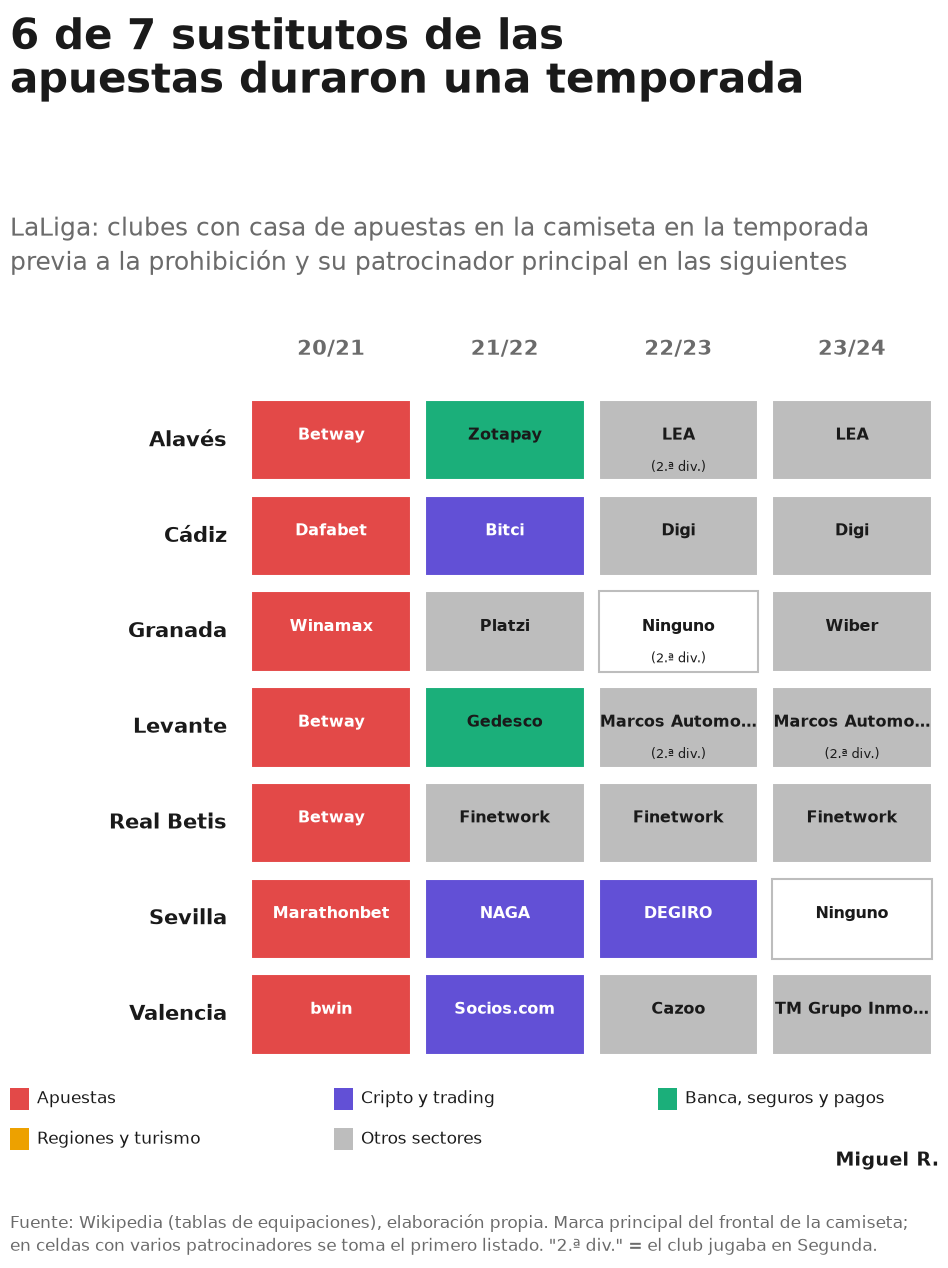

In [14]:
# Charts 2 and 4 — club-by-club grids
def grid_chart(table, seasons, title, subtitle, source, name, footnotes=None):
    n = len(table)
    fig, _ = canvas(title, subtitle, source, axes_rect=None)
    ax = fig.add_axes([0.07, 0.17, 0.86, 0.56])
    ax.set_xlim(0, len(seasons) + 1.35)
    ax.set_ylim(n, -0.9)
    ax.axis('off')
    for j, y in enumerate(seasons):
        ax.text(1.35 + j + 0.5, -0.45, season_lbl(y), ha='center', va='center', fontsize=15, color=MUTED, fontweight='bold')
    for i, (team, row) in enumerate(table.iterrows()):
        ax.text(1.25, i + 0.5, team, ha='right', va='center', fontsize=15, color=INK, fontweight='bold')
        for j, y in enumerate(seasons):
            cell = row.get(y)
            x0 = 1.35 + j
            if cell is None:
                ax.text(x0 + 0.5, i + 0.5, '—', ha='center', va='center', color=MUTED, fontsize=13)
                continue
            brand, sgroup, tier = cell
            face = SECTOR_COLOR.get(sgroup, GREY)
            ax.add_patch(Rectangle((x0 + 0.04, i + 0.08), 0.92, 0.84, facecolor=face if face != 'white' else 'white',
                                   edgecolor=GREY if face == 'white' else 'white', lw=1.5))
            label = t('Ninguno', 'None') if brand == 'NO SPONSOR' else brand
            label = label if len(label) <= 14 else label[:13] + '…'
            txt_col = 'white' if sgroup in ('Betting', 'Crypto & trading') else INK
            ax.text(x0 + 0.5, i + 0.45, label, ha='center', va='center', fontsize=11.5, color=txt_col, fontweight='bold')
            if tier == 2:
                ax.text(x0 + 0.5, i + 0.78, t('(2.ª div.)', '(2nd tier)'), ha='center', va='center', fontsize=9.5, color=txt_col)
    # legend
    legend = [('Betting', t('Apuestas', 'Betting')), ('Crypto & trading', t('Cripto y trading', 'Crypto & trading')),
              ('Banking & insurance', t('Banca, seguros y pagos', 'Banking, insurance & payments')),
              ('Regions & tourism boards', t('Regiones y turismo', 'Regions & tourism')), ('Other sectors', t('Otros sectores', 'Other sectors'))]
    for k, (gname, lab) in enumerate(legend):
        xx = 0.07 + (k % 3) * 0.30
        yy = 0.135 - (k // 3) * 0.03
        fig.patches.append(Rectangle((xx, yy), 0.018, 0.016, transform=fig.transFigure, facecolor=SECTOR_COLOR[gname], edgecolor='none'))
        fig.text(xx + 0.025, yy + 0.008, lab, fontsize=12.5, color=INK, va='center')
    save(fig, name, tight=False)
    plt.show()

base_s = BAN['Spain'] - 1
grid_chart(spain, list(range(base_s, base_s + 4)),
           t(f'{n_short} de {len(repl)} sustitutos de las\napuestas duraron una temporada',
             f'{n_short} of {len(repl)} betting replacements\nlasted one season'),
           t('LaLiga: clubes con casa de apuestas en la camiseta en la temporada\nprevia a la prohibición y su patrocinador principal en las siguientes',
             'LaLiga: clubs with a betting sponsor in the last season before the ban\nand their main shirt sponsor afterwards'),
           t('Fuente: Wikipedia (tablas de equipaciones), elaboración propia. Marca principal del frontal de la camiseta;\n'
             'en celdas con varios patrocinadores se toma el primero listado. "2.ª div." = el club jugaba en Segunda.',
             'Source: Wikipedia kit tables, own analysis. Main front-of-shirt brand; when several are listed, the first one.\n'
             '"2nd tier" = the club played in Segunda.'),
           'linkedin_2_laliga_replacements')

Saved proyecto_patrocinios/phase2/figures/linkedin_3_survival_by_sector.png


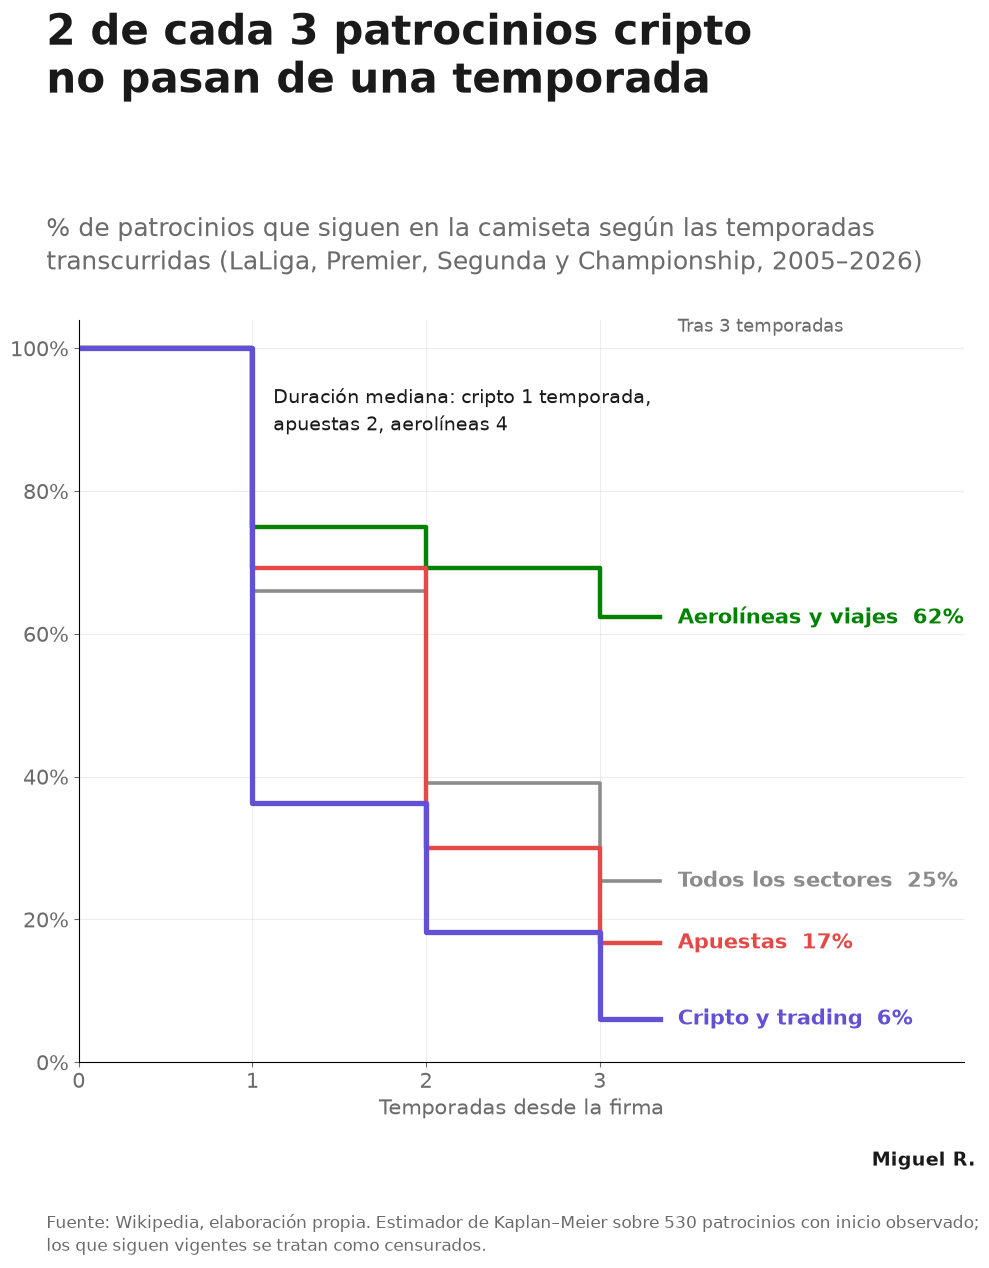

In [15]:
# Chart 3 — how long sponsorships last
crypto_gone = (1 - km_table.loc['Crypto & trading', 'still_after_1']) * 100
fig, ax = canvas(t('2 de cada 3 patrocinios cripto\nno pasan de una temporada', '2 in 3 crypto sponsorships\nend after one season'),
                 t('% de patrocinios que siguen en la camiseta según las temporadas\ntranscurridas (LaLiga, Premier, Segunda y Championship, 2005–2026)',
                   '% of sponsorships still on the shirt after each season\n(LaLiga, Premier League, Segunda, Championship, 2005–2026)'),
                 t(f'Fuente: Wikipedia, elaboración propia. Estimador de Kaplan–Meier sobre {len(sp)} patrocinios con inicio observado;\n'
                   'los que siguen vigentes se tratan como censurados.',
                   f'Source: Wikipedia, own analysis. Kaplan–Meier estimator on {len(sp)} sponsorships with an observed start;\n'
                   'ongoing ones are censored.'))
series = [('All sectors', '#8C8C8C', t('Todos los sectores', 'All sectors'), 2.6),
          ('Airlines & travel', GREEN, t('Aerolíneas y viajes', 'Airlines & travel'), 3.2),
          ('Betting', RED, t('Apuestas', 'Betting'), 3.2),
          ('Crypto & trading', VIOLET, t('Cripto y trading', 'Crypto & trading'), 3.8)]
XMAX = 3
for key, col, lab, lw in series:
    s_ = KM[key].iloc[:, 0]
    s_ = s_[s_.index <= XMAX]
    xs = list(s_.index) + [XMAX + 0.35]
    ys = list(s_.values * 100) + [s_.values[-1] * 100]
    ax.step(xs, ys, where='post', color=col, lw=lw)
    ax.text(XMAX + 0.45, ys[-1], f'{lab}  {ys[-1]:.0f}%', color=col, fontsize=15, fontweight='bold', va='center')
ax.set_xlim(0, XMAX + 2.1)
ax.set_ylim(0, 104)
ax.set_xticks(range(0, XMAX + 1))
ax.set_xlabel(t('Temporadas desde la firma', 'Seasons since signing'), fontsize=15, color=MUTED)
ax.yaxis.set_major_formatter(lambda v, _: f'{v:.0f}%')
med = km_table.median_seasons
ax.text(1.12, 95, t(f"Duración mediana: cripto {num(med['Crypto & trading'])} temporada,\napuestas {num(med['Betting'])}, aerolíneas {num(med['Airlines & travel'])}",
                    f"Median length: crypto {num(med['Crypto & trading'])} season,\nbetting {num(med['Betting'])}, airlines {num(med['Airlines & travel'])}"),
        fontsize=14, color=INK, va='top', linespacing=1.4)
ax.text(XMAX + 0.45, 103, t('Tras 3 temporadas', 'After 3 seasons'), fontsize=13, color=MUTED, va='center')
save(fig, 'linkedin_3_survival_by_sector', tight=False)
plt.show()

Saved proyecto_patrocinios/phase2/figures/linkedin_4_premier_replacements.png


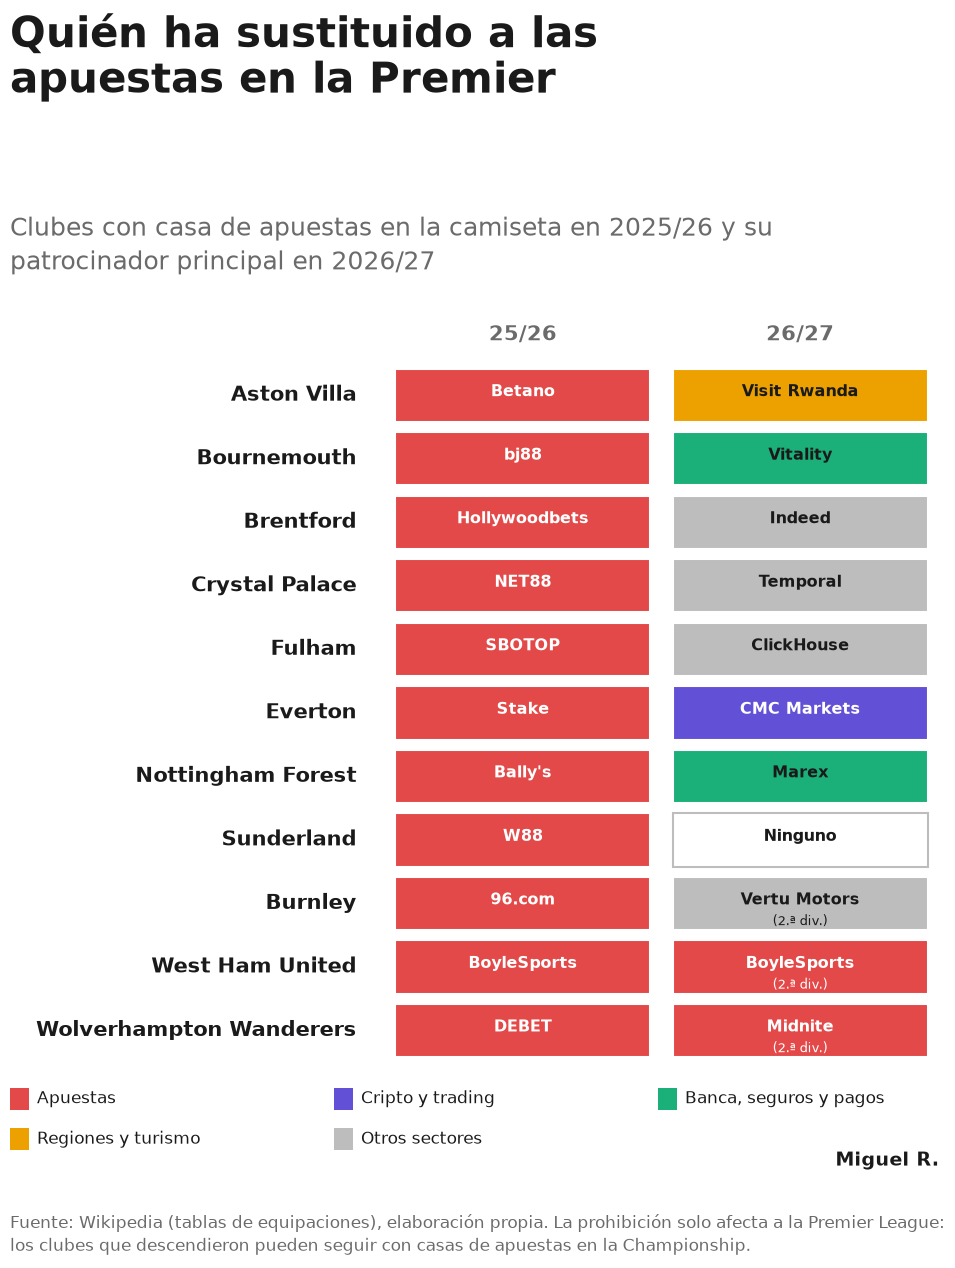

In [16]:
# Chart 4 — the Premier League now
eng_tab = england.loc[eng.sort_values('division_2026_27').team]
grid_chart(eng_tab, [BAN['England'] - 1, BAN['England']],
           t('Quién ha sustituido a las\napuestas en la Premier', 'Who replaced betting in\nthe Premier League'),
           t('Clubes con casa de apuestas en la camiseta en 2025/26 y su\npatrocinador principal en 2026/27',
             'Clubs with a betting sponsor in 2025/26 and their main shirt\nsponsor in 2026/27'),
           t('Fuente: Wikipedia (tablas de equipaciones), elaboración propia. La prohibición solo afecta a la Premier League:\n'
             'los clubes que descendieron pueden seguir con casas de apuestas en la Championship.',
             'Source: Wikipedia kit tables, own analysis. The ban only applies to the Premier League: relegated clubs can keep\n'
             'betting brands in the Championship.'),
           'linkedin_4_premier_replacements')

## 7. Key numbers

In [17]:
h = hazard
summary = pd.DataFrame([
    ('Betting share of top-flight shirts, LaLiga peak', betting.Spain.max(), '%', season_lbl(betting.Spain.idxmax())),
    ('Betting share, LaLiga last season before ban', betting.Spain.loc[BAN['Spain'] - 1], '%', season_lbl(BAN['Spain'] - 1)),
    ('Betting share, Premier League last season before ban', betting.England.loc[BAN['England'] - 1], '%', season_lbl(BAN['England'] - 1)),
    ('Clubs changing main sponsor each season', risk.changed.mean() * 100, '%', 'all divisions'),
    ('LaLiga betting replacements that lasted one season', n_short, f'of {len(repl)}', season_lbl(BAN['Spain'])),
    ('Median sponsorship length, crypto & trading', km_table.loc['Crypto & trading', 'median_seasons'], 'seasons', 'Kaplan–Meier'),
    ('Median sponsorship length, betting', km_table.loc['Betting', 'median_seasons'], 'seasons', 'Kaplan–Meier'),
    ('Median sponsorship length, airlines & travel', km_table.loc['Airlines & travel', 'median_seasons'], 'seasons', 'Kaplan–Meier'),
    ('Median sponsorship length, all sectors', km_table.loc['All sectors', 'median_seasons'], 'seasons', 'Kaplan–Meier'),
    ('Odds ratio of leaving, crypto vs other (robust)', h.loc['C(sg)[T.Crypto & trading]', 'odds_ratio_robust'], 'x', f"p={h.loc['C(sg)[T.Crypto & trading]', 'p_value_robust']:.3f}"),
    ('Odds ratio of leaving, airlines vs other (robust)', h.loc['C(sg)[T.Airlines & travel]', 'odds_ratio_robust'], 'x', f"p={h.loc['C(sg)[T.Airlines & travel]', 'p_value_robust']:.3f}"),
    ('Odds ratio of leaving, betting vs other (robust)', h.loc['C(sg)[T.Betting]', 'odds_ratio_robust'], 'x', f"p={h.loc['C(sg)[T.Betting]', 'p_value_robust']:.3f}"),
    ('Odds ratio of leaving after relegation (robust)', h.loc['relegated', 'odds_ratio_robust'], 'x', f"p={h.loc['relegated', 'p_value_robust']:.3f}"),
    ('Odds ratio of leaving after promotion (robust)', h.loc['promoted', 'odds_ratio_robust'], 'x', f"p={h.loc['promoted', 'p_value_robust']:.3f}"),
    ('Premier League replacements expected on the shirt in 2027/28', expected, f'of {len(stay)}', 'sector averages'),
], columns=['metric', 'value', 'unit', 'note'])
summary.to_csv(OUT / 'results_summary.csv', index=False)
km_table.to_csv(OUT / 'km_by_sector.csv')
hazard.to_csv(OUT / 'hazard_model.csv')
repl.to_csv(OUT / 'laliga_betting_replacements.csv', index=False)
eng.to_csv(OUT / 'premier_betting_replacements.csv', index=False)
display(summary.round(2))

,metric,value,unit,note
0,"Betting share of top-flight shirts, LaLiga peak",50.00,%,19/20
1,"Betting share, LaLiga last season before ban",35.00,%,20/21
2,"Betting share, Premier League last season befo...",55.00,%,25/26
3,Clubs changing main sponsor each season,35.09,%,all divisions
4,LaLiga betting replacements that lasted one se...,6.00,of 7,21/22
5,"Median sponsorship length, crypto & trading",1.00,seasons,Kaplan–Meier
6,"Median sponsorship length, betting",2.00,seasons,Kaplan–Meier
7,"Median sponsorship length, airlines & travel",4.00,seasons,Kaplan–Meier
8,"Median sponsorship length, all sectors",2.00,seasons,Kaplan–Meier
9,"Odds ratio of leaving, crypto vs other (robust)",3.53,x,p=0.001


### Limitations
1. **Duration and turnover, not money.** Contract values are not public consistently.
2. **Wikipedia as a source.** Community-edited; the revision ID of each page is stored so the dataset can be rebuilt and audited. Cells listing several sponsors were resolved with one fixed rule (first listed / home kit).
3. **Segunda 2005–2009 is missing** (no kits table on Wikipedia). Clubs in Segunda in those seasons are censored.
4. **Small numbers in the ban cases:** 7 clubs in LaLiga and 11 in the Premier League. They are cases, not a statistical sample; the Kaplan–Meier and hazard results use the full panel.
5. **Sector tags are judgement calls** for some brands (e.g. payment processors, "sports-news" brands with links to online gaming). They are listed in `sponsor_tags.csv` with notes.